In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV,ElasticNetCV, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("cars.csv")
df.head()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid
0,2001,8.17,4000,Petrol,4,8587.64,Chevrolet,Manual,White,NaN,0,No
1,2014,17.59,1500,Petrol,4,5943.50,Honda,Manual,Black,NaN,0,Yes
2,2023,18.09,2500,Diesel,5,9273.58,BMW,Automatic,Black,Full,1,Yes
3,2009,11.28,800,Petrol,1,6836.24,Hyundai,Manual,Blue,Full,0,Yes
4,2005,12.23,1000,Petrol,2,4625.79,Nissan,Automatic,Red,Full,0,Yes


In [3]:
df.columns

Index(['make_year', 'mileage_kmpl', 'engine_cc', 'fuel_type', 'owner_count',
       'price_usd', 'brand', 'transmission', 'color', 'service_history',
       'accidents_reported', 'insurance_valid'],
      dtype='str')

In [4]:
df = pd.read_csv("cars.csv")


X = df.drop(['price_usd'], axis=1)
X = pd.get_dummies(X, drop_first=True)

y = df["price_usd"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train=scaler.fit_transform(X_train) 
X_test=scaler.transform(X_test)

corr_matrix = X.corr()

print("Матрица корреляций")
display(corr_matrix.round(2))

Матрица корреляций


,make_year,mileage_kmpl,engine_cc,owner_count,accidents_reported,fuel_type_Electric,fuel_type_Petrol,brand_Chevrolet,brand_Ford,brand_Honda,...,brand_Toyota,brand_Volkswagen,transmission_Manual,color_Blue,color_Gray,color_Red,color_Silver,color_White,service_history_Partial,insurance_valid_Yes
make_year,1.00,-0.01,-0.02,-0.02,-0.01,-0.01,0.02,0.01,0.00,0.00,...,0.00,0.00,0.00,0.01,0.00,0.01,-0.02,-0.00,-0.02,0.00
mileage_kmpl,-0.01,1.00,-0.00,-0.01,0.00,0.01,-0.01,-0.01,-0.00,-0.00,...,-0.00,0.00,-0.01,0.01,-0.01,-0.01,-0.01,-0.01,-0.01,0.02
engine_cc,-0.02,-0.00,1.00,-0.00,-0.01,-0.01,-0.01,0.00,0.02,-0.01,...,-0.00,0.01,-0.00,0.01,0.01,0.00,-0.01,-0.02,0.00,-0.01
owner_count,-0.02,-0.01,-0.00,1.00,-0.01,-0.00,0.01,-0.01,0.01,-0.02,...,-0.01,0.01,0.01,0.01,-0.01,-0.01,0.01,0.00,0.00,0.00
accidents_reported,-0.01,0.00,-0.01,-0.01,1.00,0.01,-0.01,-0.00,-0.02,-0.01,...,0.00,-0.01,-0.00,0.01,0.01,-0.01,-0.01,-0.00,0.00,-0.02
fuel_type_Electric,-0.01,0.01,-0.01,-0.00,0.01,1.00,-0.33,-0.00,0.01,0.00,...,-0.02,-0.01,0.01,-0.00,-0.02,0.02,-0.01,0.01,-0.01,0.01
fuel_type_Petrol,0.02,-0.01,-0.01,0.01,-0.01,-0.33,1.00,0.01,0.00,0.01,...,0.00,0.01,0.00,0.01,-0.01,-0.01,0.02,-0.01,0.01,-0.00
brand_Chevrolet,0.01,-0.01,0.00,-0.01,-0.00,-0.00,0.01,1.00,-0.11,-0.11,...,-0.11,-0.11,-0.01,0.00,0.01,0.02,-0.01,-0.01,0.00,0.00
brand_Ford,0.00,-0.00,0.02,0.01,-0.02,0.01,0.00,-0.11,1.00,-0.11,...,-0.11,-0.11,-0.01,-0.00,0.00,0.00,-0.02,0.01,0.01,-0.01
brand_Honda,0.00,-0.00,-0.01,-0.02,-0.01,0.00,0.01,-0.11,-0.11,1.00,...,-0.11,-0.11,-0.00,-0.00,0.00,-0.00,-0.01,0.01,0.00,0.01


In [5]:
lr = LinearRegression()
lr.fit(X_train, y_train)

alphas_to_test = [0.1, 1.0, 10.0, 100.0, 1000.0, 2000.0, 3000.0, 5000.0, 10000.0]
ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train, y_train)


lasso_cv =LassoCV(alphas=alphas_to_test, random_state=42)
lasso_cv.fit(X_train, y_train)
lasso =Lasso(alpha=5000.0, random_state=42)
lasso.fit(X_train, y_train)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
elastic_cv = ElasticNetCV(l1_ratio=l1_ratios, alphas=alphas_to_test, cv=5, random_state=42)
elastic_cv.fit(X_train, y_train)

print(f"alpha l2= {ridge_cv.alpha_}")
print(f"alpha l1 = {lasso_cv.alpha_}")
print(f"alpha l1/l2 = {elastic_cv.alpha_}")
print(f"Оптимальное соотношение L1/L2 (l1_ratio): {elastic_cv.l1_ratio_}")

print("Веса OLS")
print(np.round(lr.coef_, 0))
print("Веса Ridge (L2)")
print(np.round(ridge_cv.coef_, 0))
print("Веса Lasso (L1)")
print(np.round(lasso_cv.coef_, 0))
print("Веса Lasso (L1) (alpha = 5000)")
print(np.round(lasso.coef_, 0))
print("Веса ElasticNet:")
print(np.round(elastic_cv.coef_, 0))

alpha l2= 1.0
alpha l1 = 10.0
alpha l1/l2 = 0.1
Оптимальное соотношение L1/L2 (l1_ratio): 0.99
Веса OLS
[1248.  606. 1927. -694.    3.  903.   -2.  -24.  -24.  -13.  -27.  -18.
  -19.  -33.  -21.   -5.   -7.  -19.  -15.   10.  -16.   -3.   -0.  -14.]
Веса Ridge (L2)
[1248.  606. 1927. -694.    3.  902.   -2.  -24.  -24.  -13.  -27.  -18.
  -19.  -33.  -21.   -5.   -7.  -19.  -15.   10.  -16.   -3.   -0.  -14.]
Веса Lasso (L1)
[ 1.237e+03  5.960e+02  1.917e+03 -6.850e+02  0.000e+00  8.930e+02
 -0.000e+00 -0.000e+00 -0.000e+00  0.000e+00 -0.000e+00 -0.000e+00
 -0.000e+00 -6.000e+00 -0.000e+00  4.000e+00 -0.000e+00 -1.000e+00
 -0.000e+00  1.100e+01 -0.000e+00  0.000e+00 -0.000e+00 -4.000e+00]
Веса Lasso (L1) (alpha = 5000)
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Веса ElasticNet:
[1246.  606. 1925. -693.    3.  901.   -2.  -23.  -22.  -12.  -26.  -17.
  -17.  -32.  -20.   -4.   -7.  -18.  -15.   10.  -16.   -3.   -0.  -14.]


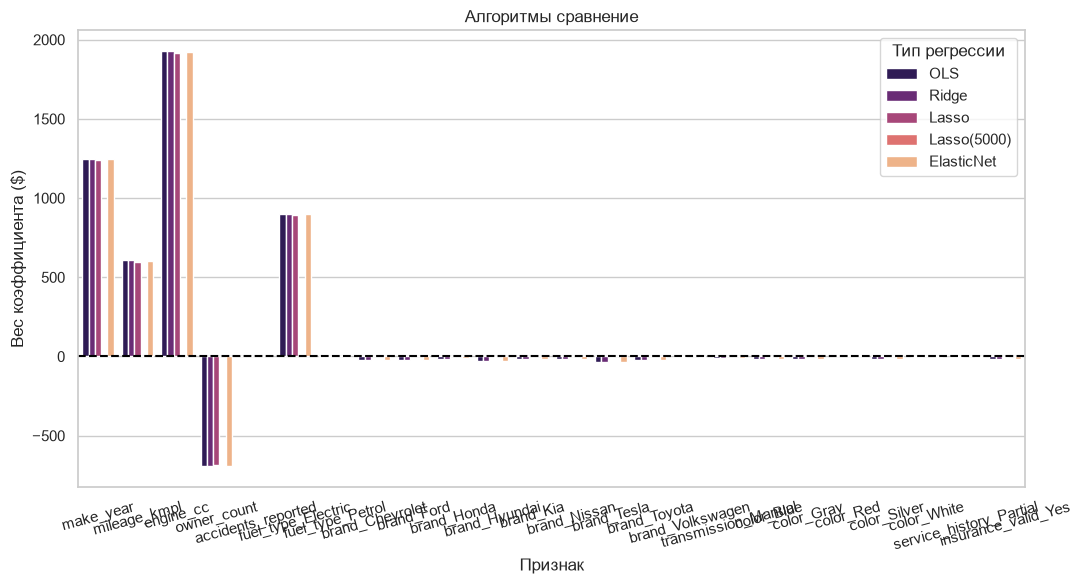

In [6]:
weights_df = pd.DataFrame(
    {
        "Признак" : X.columns,
        "OLS" : lr.coef_,
        "Ridge" : ridge_cv.coef_,
        "Lasso" : lasso_cv.coef_,
        "Lasso(5000)" : lasso.coef_,
        "ElasticNet": elastic_cv.coef_
    }
)
weights_melted = weights_df.melt(
    id_vars="Признак", var_name="Модель", value_name="Влияние на цену (Вес)" 
)
plt.figure(figsize=(11,6))
sns.barplot(
    data=weights_melted,
    x="Признак",
    y="Влияние на цену (Вес)",
    hue="Модель",
    palette="magma"
)

plt.axhline(0, color="black", lw=1.5, ls="--")
plt.title("Алгоритмы сравнение")
plt.ylabel("Вес коэффициента ($)", fontsize=12)
plt.xticks(rotation=15)
plt.legend(title="Тип регрессии")
plt.tight_layout()
plt.show()


In [7]:
print(f"R2 для OLS: {r2_score(y_test, lr.predict(X_test)):.4f}")
print(f"R2 для Ridge: {r2_score(y_test, ridge_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso.predict(X_test)):.4f}")
print(f"R2 для ElasticNet: {r2_score(y_test, elastic_cv.predict(X_test)):.4f}")

R2 для OLS: 0.8766
R2 для Ridge: 0.8766
R2 для Lasso: 0.8765
R2 для Lasso: -0.0009
R2 для ElasticNet: 0.8766


Ридж и элстикнет показывает, что основное влияние на стоимость оказывают 5 показателей: год выпуска, пробег, объем двигателя, кол-во владельцев, тип топлива. Из показетелей лишь кол-во владельцев влияет отрицательно.